# 06 — Training on the whole corpus, and comparing with counting

**Chapter 1** · suggested time: 25 min · CPU only (about 2 min of execution) · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_1/06_training_and_comparison.ipynb)

![Chapter roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/00_roadmap.png)

In notebook 05, we took **one** learning step on the 5 bigrams of `emma`. We now move to **all** the bigrams of `names.txt`, and we repeat the step about a hundred times.

![The training loop](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/06_loop.png)

**The big question of this notebook:** starting from a random matrix, and without ever seeing the table `N`, does gradient descent recover the probabilities from counting?

In [1]:
# On Google Colab: fetch the course repository (corpus + shared modules such as bigram.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("bigram.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_1

In [2]:
# Setup: imports and the chapter's small shared module
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigram  # the file bigram.py, next to this notebook
from bigram import SEED, plot_char_matrix

words = bigram.load_names()
chars, stoi, itos = bigram.build_vocabulary(words)
print(f"{len(words):,} names · vocabulary of {len(stoi)} symbols · PyTorch {torch.__version__}")
from bigram import forward_from_indices, nll_from_probs

N = bigram.count_bigrams(words, stoi)
P = N.float() / N.sum(dim=1, keepdim=True)

32,033 names · vocabulary of 27 symbols · PyTorch 2.15.0+cu132


## 1. All the examples of the corpus

- `xs`: the index of the current character, for **every** bigram of the corpus;
- `ys`: the index of the true next character;
- `M = len(ys)`: the **number of transitions** (not 27, not the number of names);
- `torch.arange(M)`: the `M` row numbers, and `ys` the `M` columns to read.

A **single line** computes the probability of the correct answer for every observation, exactly as on `emma`:

```python
loss = -probs[torch.arange(M), ys].log().mean()
```

In [3]:
xs, ys = bigram.build_examples(words, stoi)
M = len(ys)
xenc = F.one_hot(xs, num_classes=27).float()

print(f"Names: {len(words):,}  ·  transitions M: {M:,}")
print("xs:", tuple(xs.shape), "| ys:", tuple(ys.shape), "| xenc:", tuple(xenc.shape))
print("The first 5 examples:", [f"{itos[a]}→{itos[b]}" for a, b in zip(xs[:5].tolist(), ys[:5].tolist())])

counting_loss = -P[xs, ys].log().mean().item()
print(f"\nBaseline to beat (or match): counting loss = {counting_loss:.4f}")

Names: 32,033  ·  transitions M: 228,146
xs: (228146,) | ys: (228146,) | xenc: (228146, 27)
The first 5 examples: ['.→e', 'e→m', 'm→m', 'm→a', 'a→.']

Baseline to beat (or match): counting loss = 2.4540


## 2. The training loop

Each iteration chains the five steps of notebook 05:
1. **forward**: `W → logits → probabilities`;
2. **loss**: one column per row, then the mean NLL;
3. **reset**: `W.grad = None`;
4. **backward**: `loss.backward()` fills `W.grad`;
5. **update**: `W -= lr * W.grad` under `torch.no_grad()`.

### Mini-experiment: only the learning rate changes

For a fair comparison, all runs start **from the same 729 initial weights** and use **the same data**.

**Before running:** will the four curves follow the same trajectory? Which one will get closest to counting?

> **Nuance:** `lr = 50` works here because the model is tiny and the loss is an average over 228,000 examples, so its gradients are small. In a Transformer, such a step would be catastrophic (in chapter 2, we will use `1e-3` with AdamW). The learning rate always depends on the model and the optimizer.

In [4]:
import time

initial_W = torch.randn((27, 27), generator=torch.Generator().manual_seed(SEED))


def train_bigram(learning_rate, steps=100, W_start=None, reg=0.0):
    W = (initial_W if W_start is None else W_start).clone().detach().requires_grad_(True)
    history = []
    for step in range(steps):
        # (1) FORWARD: W -> logits -> probabilities
        logits = xenc @ W                                   # (M, 27)
        counts = logits.exp()                               # (M, 27)
        probs = counts / counts.sum(dim=1, keepdim=True)    # (M, 27)
        # (2) LOSS: one correct column per row, then the mean
        loss = -probs[torch.arange(M), ys].log().mean()     # scalar
        history.append(loss.item())
        loss = loss + reg * (W ** 2).mean()                 # regularization (section 5), zero by default
        # (3) RESET
        W.grad = None
        # (4) BACKWARD: fills W.grad, does not change W
        loss.backward()
        # (5) UPDATE: only now do we change the weights
        with torch.no_grad():
            W -= learning_rate * W.grad
    return W.detach(), history


experiments = {}
for rate in [0.1, 1.0, 10.0, 50.0]:
    t0 = time.time()
    experiments[rate] = train_bigram(rate, steps=100)
    h = experiments[rate][1]
    print(f"lr = {rate:>5}: loss {h[0]:.3f} → {h[-1]:.4f}   ({time.time() - t0:.1f} s)")

lr =   0.1: loss 3.759 → 3.6733   (11.9 s)


lr =   1.0: loss 3.759 → 3.1887   (11.8 s)


lr =  10.0: loss 3.759 → 2.5764   (12.4 s)


lr =  50.0: loss 3.759 → 2.4729   (10.0 s)


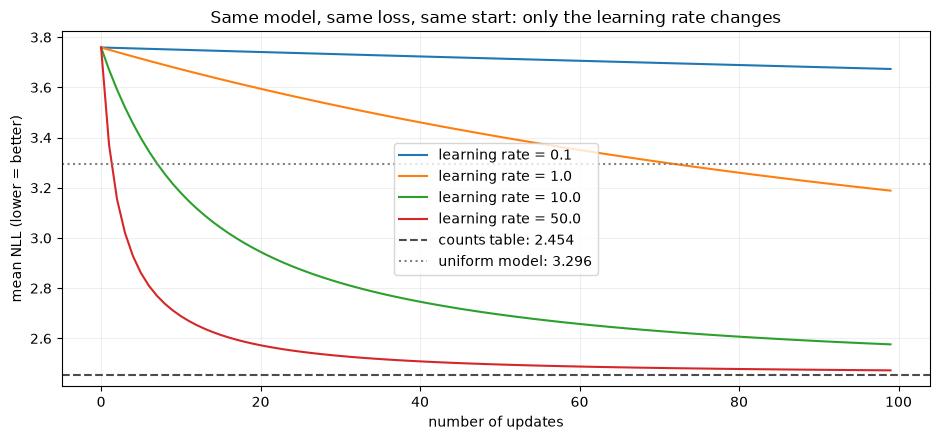

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for rate, (_, history) in experiments.items():
    ax.plot(history, label=f"learning rate = {rate}")
ax.axhline(counting_loss, color="black", linestyle="--", alpha=0.7, label=f"counts table: {counting_loss:.3f}")
ax.axhline(math.log(27), color="gray", linestyle=":", label="uniform model: 3.296")
ax.set(xlabel="number of updates", ylabel="mean NLL (lower = better)",
       title="Same model, same loss, same start: only the learning rate changes")
ax.grid(alpha=0.2); ax.legend(); plt.tight_layout(); plt.show()

### Reading the curves

**What the plot shows:** the four runs optimize **the same loss** from **the same start**. With `0.1`, there is almost no visible progress in 100 steps. With `50`, we get very close to counting.

Notice also that the **starting** loss (≈ 3.76) is **worse than uniform** (3.30). A random `W` is not "neutral": it has arbitrary preferences, and they are wrong. We will come back to initialization in chapter 2.

**What the plot does not show:** that the 27 probabilities of **each row** are the same as those from counting. Two models can have a similar loss without having identical tables. Let's check.

### What if we keep going?

In [6]:
W_50, h_50 = experiments[50.0]
W_long, h_long = train_bigram(50.0, steps=300, W_start=W_50)
print(f"After 100 steps: {h_50[-1]:.4f}")
print(f"After 400 steps: {h_long[-1]:.4f}")
print(f"Counting       : {counting_loss:.4f}")

After 100 steps: 2.4729
After 400 steps: 2.4578
Counting       : 2.4540


## 3. Has the network recovered the counts table?

![Two paths](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/06_two_paths.png)

For a fixed current character (`a`), we compare **the 27 probabilities**:
- **counting**: `P[stoi['a']]`, the proportions in `names.txt`;
- **network**: `softmax(W_trained[stoi['a']])`, the weights adjusted by gradient.

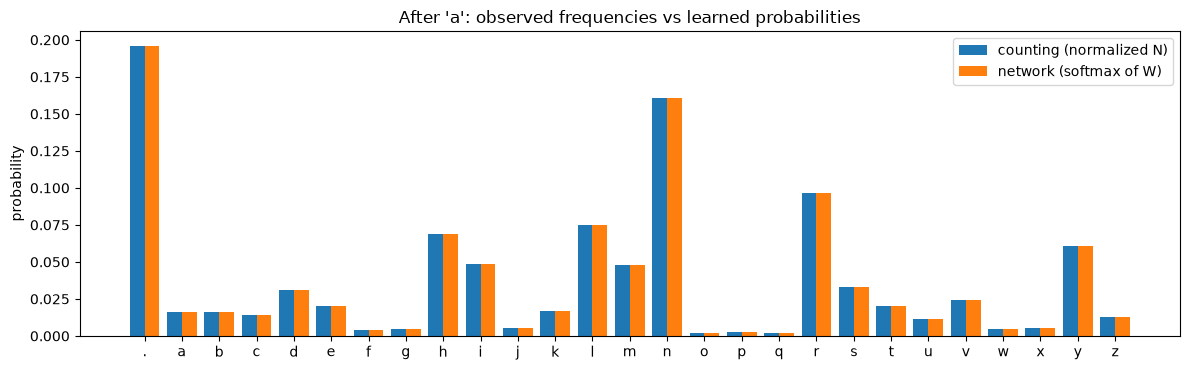

Loss: counting 2.4540 · network 2.4578
Mean absolute difference between the two tables: 0.00172


In [7]:
W_trained = W_long
with torch.no_grad():
    learned_probs = F.softmax(W_trained, dim=1)       # the network's "table": one row per character

current_char = "a"            # try 'e', 'm', '.', 'q'…
i = stoi[current_char]
x = torch.arange(27).numpy()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(x - .2, P[i].numpy(), width=.4, label="counting (normalized N)")
ax.bar(x + .2, learned_probs[i].numpy(), width=.4, label="network (softmax of W)")
ax.set_xticks(x, [itos[j] for j in range(27)])
ax.set(title=f"After '{current_char}': observed frequencies vs learned probabilities", ylabel="probability")
ax.legend(); plt.tight_layout(); plt.show()

network_loss = -learned_probs[xs, ys].log().mean().item()
print(f"Loss: counting {counting_loss:.4f} · network {network_loss:.4f}")
print(f"Mean absolute difference between the two tables: {(P - learned_probs).abs().mean().item():.5f}")

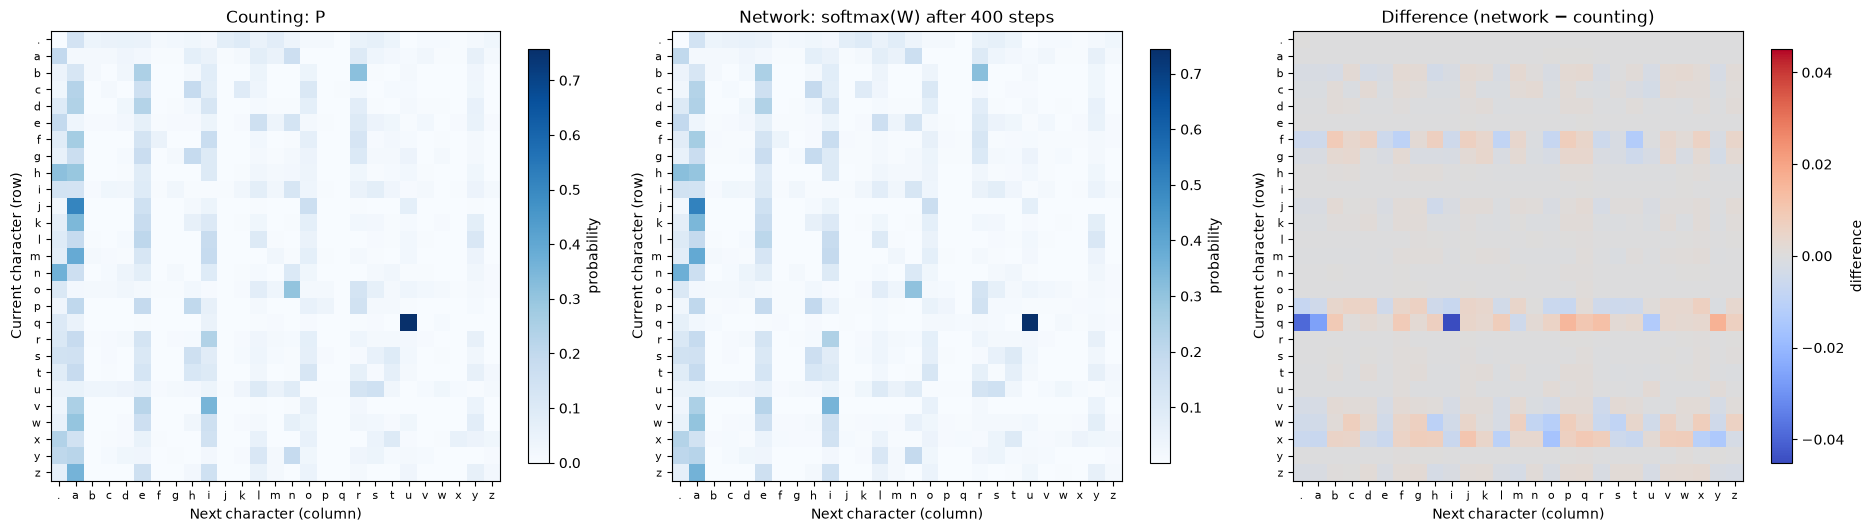

Least observed rows: [('q', 272), ('x', 697), ('f', 905)]
Most different rows: ['q', 'x', 'w']


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
plot_char_matrix(P, itos, title="Counting: P", cbar_label="probability", ax=axes[0])
plot_char_matrix(learned_probs, itos, title="Network: softmax(W) after 400 steps",
                 cbar_label="probability", ax=axes[1])
diff = learned_probs - P
lim = diff.abs().max().item()
plot_char_matrix(diff, itos, title="Difference (network − counting)",
                 cbar_label="difference", cmap="coolwarm", ax=axes[2], vmin=-lim, vmax=lim)
plt.tight_layout(); plt.show()

rare_rows = N.sum(dim=1).argsort()[:3]
diff_per_row = (P - learned_probs).abs().sum(dim=1)
print("Least observed rows:", [(itos[k.item()], N[k].sum().item()) for k in rare_rows])
print("Most different rows:", [itos[k.item()] for k in diff_per_row.argsort(descending=True)[:3]])

**What does this comparison prove?** The two maps are almost indistinguishable. The network **learned the bigram frequencies** from the loss alone: it never saw `N`. This is not a memory of the names: the model only keeps the last character.

**Nuances:**
- a transition **never observed** has probability 0 in the table, whereas a softmax of finite weights always gives a **strictly positive** probability. So we speak of **close** distributions, not equal ones;
- rarely observed rows converge more slowly: few examples, so little gradient.

## 4. Generating with the trained network

No new logic is needed: `learned_probs` is a probability table, just like `P`. We reuse **the same generation function** as in notebook 01, with the same seed.

In [9]:
print("Counting:", bigram.generate_names(P, itos, n=10, seed=42))
print("Network :", bigram.generate_names(learned_probs, itos, n=10, seed=42))

Counting: ['anugeenvi', 's', 'mabian', 'dan', 'stan', 'silaylelaremah', 'li', 'le', 'epiachalen', 'diza']
Network : ['anugeenvi', 's', 'mabian', 'dan', 'stan', 'silaylelaremah', 'li', 'le', 'epiachalen', 'diza']


With the same seed, the two models produce **the same names**. This is very concrete evidence that the two tables are close: every draw lands on the same character. Differences would eventually appear if we generated more, when a draw lands very close to the boundary between two characters.

## 5. Going further: regularization, a cousin of smoothing

In notebook 02, adding fake counts (`N + k`) pulled each row towards uniform. For the network, the equivalent is to **push the weights towards 0**. If all the logits of a row are equal, the softmax is uniform. So we add a penalty `reg × mean(W²)` to the loss:

$$
\mathcal L_\text{total} = \text{NLL} + \lambda\cdot\overline{W^2}.
$$

The larger $\lambda$, the more "smoothed" the distributions. In chapter 2, AdamW's *weight decay* plays this role.

In [10]:
for reg in [0.0, 0.1, 1.0]:
    W_r, h_r = train_bigram(50.0, steps=100, reg=reg)
    p_r = F.softmax(W_r, dim=1)
    print(f"λ = {reg:<4}: NLL = {h_r[-1]:.4f} · smallest probability in the table = {p_r.min().item():.1e}"
          f" · max |W| = {W_r.abs().max().item():.2f}")

λ = 0.0 : NLL = 2.4729 · smallest probability in the table = 9.8e-04 · max |W| = 3.97


λ = 0.1 : NLL = 2.5055 · smallest probability in the table = 3.8e-03 · max |W| = 3.26


λ = 1.0 : NLL = 2.7213 · smallest probability in the table = 1.4e-02 · max |W| = 2.43


Regularization raises the NLL on the corpus a little, but it **keeps the weights smaller** (max |W| goes from about 4 to 2.4). It also avoids near-zero probabilities. This is exactly the smoothing trade-off: we accept fitting the data a little less closely in order to be less categorical.

## Summary: what you should be able to explain without looking at the code

| | counting model | neural model |
|---|---|---|
| formula | $P_{ij}=\dfrac{N_{ij}}{\sum_k N_{ik}}$ | $P_{ij}(W)=\dfrac{e^{W_{ij}}}{\sum_k e^{W_{ik}}}$ |
| obtained by | a direct calculation | minimizing the NLL by gradient descent |
| parameters | 729 counters | 729 weights |
| loss on `names.txt` | 2.454 | ≈ 2.46 after 400 steps |
| zeros | yes (unless smoothed) | never (softmax) |
| smoothing | `N + k` | regularization `λ·W²` |

**The four invariants for the rest of the course:**
1. the model produces **logits**;
2. the **softmax** turns them into probabilities;
3. the **mean NLL** measures the prediction errors;
4. **gradient descent** adjusts the weights to lower it.

These four lines will stay **exactly** the same for the Transformer in chapter 2. Only the way the logits are computed changes.

**Back to the opening question:** why learn a table we already know how to compute? Because counting **does not scale**. With a context of 8 characters, we would need $27^8 \approx 2.8 \times 10^{11}$ rows, almost all of them empty. A network, on the other hand, can **share** what it learns across similar contexts. That is the subject of chapter 2: more context, without counting everything.

## Appendix — Self-check (after class)

Without running any code:
1. Why does `P[stoi['a']]` contain 27 values that sum to 1?
2. What is the shape of `xenc @ W` for a batch of 200 bigrams?
3. Why does the NLL blow up when the model gives a tiny probability to the correct answer?
4. Why does the update follow `−W.grad` and not `+W.grad`?
5. Why is the gradient of row `q` of `W` zero when we train only on `emma`?
6. Which limitation of the bigram will chapter 2 remove?

**Small coding challenge:** change `current_char` to `e`, `m`, `.` or `q` in the comparison. Which rows are learned best? Why?

## References
- Andrej Karpathy, [*The spelled-out intro to language modeling: building makemore*](https://www.youtube.com/watch?v=PaCmpygFfXo) (2022) and the [makemore](https://github.com/karpathy/makemore) repository, where `names.txt` and the spirit of this chapter come from (the training loop, the comparison with counting and the regularization follow his presentation).
- Y. Bengio et al., [*A Neural Probabilistic Language Model*](https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf), JMLR 2003: why shared parameters beat counting as the context grows.
- I. Goodfellow, Y. Bengio and A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), 2016, section 7.1 (L2 penalty = *weight decay*).
- D. Jurafsky and J. H. Martin, [*Speech and Language Processing*](https://web.stanford.edu/~jurafsky/slp3/), chapter 3 (smoothing) and chapter 7 (neural language models).